<a href="https://colab.research.google.com/github/Mufliha-Hafsyah/Machine-Learning/blob/main/Week09/Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM PEMBELAJARAN MESIN**

**Nama**  : Mufliha Hafsyah Shahieza <br>
**NIM**   : 244107020147 <br>
**Kelas** : TI-3G

---

# **JS09 - Klasifikasi**<hr>
# **Tugas 1**

1. Buatlah model klasifikasi dengan menggunakan kNN untuk mengklasifikasikan jenis suara male dan female pada dataset voice.csv.
2. Lakukan percobaan untuk mengetahui fitur-fitur yang paling optimal untuk digunakan. Fitur apa saja yang Anda gunakan untuk mendapatkan hasil terbaik?
3. Berdasarkan fitur yang telah Anda pilih pada soal nomor 2, berapa nilai  yang terbaik? Lampirkan grafika analisis dan alasan Anda.
<hr>

## **Langkah 1: Upload data**

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('voice.csv')

print(df.shape)
print(df.head())
print(df.info())
print(df.isnull().sum())
print(df['label'].value_counts())  # sesuaikan jika nama kolom targetnya berbeda

(3168, 21)
   meanfreq        sd    median       Q25       Q75       IQR       skew  \
0  0.059781  0.064241  0.032027  0.015071  0.090193  0.075122  12.863462   
1  0.066009  0.067310  0.040229  0.019414  0.092666  0.073252  22.423285   
2  0.077316  0.083829  0.036718  0.008701  0.131908  0.123207  30.757155   
3  0.151228  0.072111  0.158011  0.096582  0.207955  0.111374   1.232831   
4  0.135120  0.079146  0.124656  0.078720  0.206045  0.127325   1.101174   

          kurt    sp.ent       sfm  ...  centroid   meanfun    minfun  \
0   274.402906  0.893369  0.491918  ...  0.059781  0.084279  0.015702   
1   634.613855  0.892193  0.513724  ...  0.066009  0.107937  0.015826   
2  1024.927705  0.846389  0.478905  ...  0.077316  0.098706  0.015656   
3     4.177296  0.963322  0.727232  ...  0.151228  0.088965  0.017798   
4     4.333713  0.971955  0.783568  ...  0.135120  0.106398  0.016931   

     maxfun   meandom    mindom    maxdom   dfrange   modindx  label  
0  0.275862  0.007812 

## **Langkah 2: Encode label, split, dan scaling**

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop('label', axis=1)
y = df['label'].map({'female': 0, 'male': 1})

# Split 80:20, stratify menjaga proporsi male/female tetap sama
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Scaling: fit HANYA di data latih, lalu transform ke data uji
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(X_train.shape, X_test.shape)

(2534, 20) (634, 20)


## **Langkah 3: Model kNN dasar dengan semua fitur (soal 1)**

In [6]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_s, y_train)

print("Akurasi train:", accuracy_score(y_train, knn.predict(X_train_s)))
print("Akurasi test :", accuracy_score(y_test, knn.predict(X_test_s)))
print(confusion_matrix(y_test, knn.predict(X_test_s)))
print(classification_report(y_test, knn.predict(X_test_s)))

# Pembanding tanpa scaling (untuk bukti di laporan bahwa scaling penting)
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
print("Akurasi test tanpa scaling:", accuracy_score(y_test, knn_raw.predict(X_test)))

Akurasi train: 0.9830307813733228
Akurasi test : 0.9763406940063092
[[306  11]
 [  4 313]]
              precision    recall  f1-score   support

           0       0.99      0.97      0.98       317
           1       0.97      0.99      0.98       317

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634

Akurasi test tanpa scaling: 0.7097791798107256


### **Jawaban Soal 1: Model kNN**
Model kNN dibangun dengan semua fitur setelah dilakukan scaling (StandardScaler) dan pembagian data 80:20 (stratified). Dengan k = 5, akurasi data uji 0,976. Tanpa scaling, akurasi turun menjadi 0,710, sehingga scaling sangat diperlukan karena kNN berbasis jarak dan skala antar fitur sangat timpang.

## **Langkah 4: Percobaan pemilihan fitur (soal 2)**

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.feature_selection import SequentialFeatureSelector

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

# Percobaan 1: akurasi CV tiap fitur secara individual
skor = {}
for kol in X_train.columns:
    skor[kol] = cross_val_score(pipe, X_train[[kol]], y_train, cv=cv).mean()
rank = pd.Series(skor).sort_values(ascending=False)
print(rank)

# Percobaan 2: forward selection (menambah fitur satu per satu selama akurasi CV naik)
sfs = SequentialFeatureSelector(pipe, n_features_to_select='auto', tol=0.001,
                                direction='forward', cv=cv, scoring='accuracy')
sfs.fit(X_train, y_train)
fitur_sfs = X_train.columns[sfs.get_support()].tolist()
print("Fitur terpilih forward selection:", fitur_sfs)

# Percobaan 3: bandingkan beberapa kandidat subset fitur
kandidat = {
    'Semua fitur (20)': list(X_train.columns),
    'Top 3 individual': rank.index[:3].tolist(),
    'Top 5 individual': rank.index[:5].tolist(),
    'Top 10 individual': rank.index[:10].tolist(),
    'Forward selection': fitur_sfs,
}
for nama, kols in kandidat.items():
    s = cross_val_score(pipe, X_train[kols], y_train, cv=cv)
    print(f'{nama:20s} ({len(kols):2d} fitur): {s.mean():.4f} ± {s.std():.4f}')

meanfun     0.940803
IQR         0.898972
Q25         0.866214
sd          0.783740
sp.ent      0.716667
mode        0.663367
sfm         0.661018
maxdom      0.624312
mindom      0.617610
skew        0.616416
centroid    0.611288
meanfreq    0.611288
dfrange     0.602588
median      0.588793
meandom     0.581691
kurt        0.560779
minfun      0.540654
maxfun      0.521705
modindx     0.509864
Q75         0.502754
dtype: float64
Fitur terpilih forward selection: ['IQR', 'sfm', 'mode', 'meanfun']
Semua fitur (20)     (20 fitur): 0.9696 ± 0.0086
Top 3 individual     ( 3 fitur): 0.9736 ± 0.0060
Top 5 individual     ( 5 fitur): 0.9775 ± 0.0037
Top 10 individual    (10 fitur): 0.9755 ± 0.0044
Forward selection    ( 4 fitur): 0.9807 ± 0.0051


### **Jawaban Soal 2: Fitur apa saja yang Anda gunakan untuk mendapatkan hasil terbaik?**

Percobaan dilakukan dengan cross-validation 5-fold pada data latih (data uji tidak digunakan). Hasilnya:

| Subset fitur | Jumlah fitur | Akurasi CV |
|---|---|---|
| Semua fitur | 20 | 0,9696 ± 0,0086 |
| Top 3 individual | 3 | 0,9736 ± 0,0060 |
| Top 5 individual | 5 | 0,9775 ± 0,0037 |
| Top 10 individual | 10 | 0,9755 ± 0,0044 |
| Forward selection | 4 | **0,9807 ± 0,0051** |

Fitur yang memberikan hasil terbaik adalah `IQR`, `sfm`, `mode`, dan `meanfun` (hasil forward selection). Menggunakan seluruh fitur justru menghasilkan akurasi terendah karena fitur yang kurang informatif (misalnya `Q75`, `modindx`, `maxfun`) dan fitur yang redundan (`centroid` sama dengan `meanfreq`) menambah noise pada perhitungan jarak kNN. Fitur `meanfun` adalah fitur individual terkuat (akurasi 0,941).

## **Langkah 5: Analisis nilai k (soal 3)**

k terbaik: 5 dengan akurasi CV: 0.9806628154454241


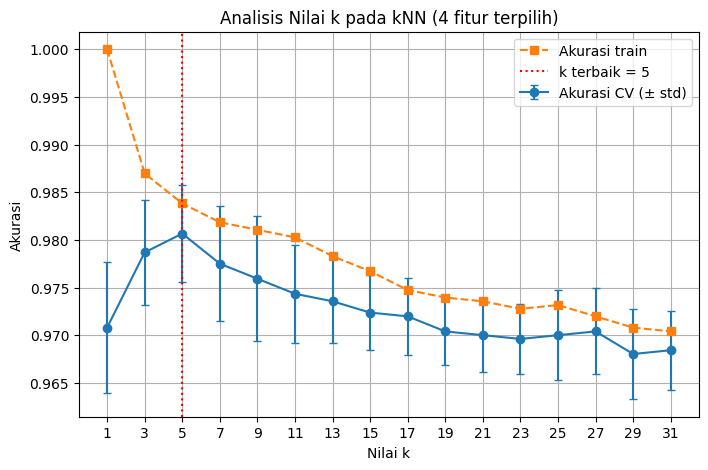

Akurasi test: 0.9889589905362776
[[313   4]
 [  3 314]]
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       317
           1       0.99      0.99      0.99       317

    accuracy                           0.99       634
   macro avg       0.99      0.99      0.99       634
weighted avg       0.99      0.99      0.99       634



In [8]:
fitur_terbaik = ['IQR', 'sfm', 'mode', 'meanfun']
k_range = list(range(1, 32, 2))

mean_cv, std_cv, acc_train = [], [], []
for k in k_range:
    pipe_k = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    s = cross_val_score(pipe_k, X_train[fitur_terbaik], y_train, cv=cv)
    mean_cv.append(s.mean())
    std_cv.append(s.std())
    pipe_k.fit(X_train[fitur_terbaik], y_train)
    acc_train.append(pipe_k.score(X_train[fitur_terbaik], y_train))

best_k = k_range[int(np.argmax(mean_cv))]
print("k terbaik:", best_k, "dengan akurasi CV:", max(mean_cv))

# Grafik analisis
plt.figure(figsize=(8,5))
plt.errorbar(k_range, mean_cv, yerr=std_cv, marker='o', capsize=3, label='Akurasi CV (± std)')
plt.plot(k_range, acc_train, marker='s', linestyle='--', label='Akurasi train')
plt.axvline(best_k, color='red', linestyle=':', label=f'k terbaik = {best_k}')
plt.xlabel('Nilai k')
plt.ylabel('Akurasi')
plt.title('Analisis Nilai k pada kNN (4 fitur terpilih)')
plt.xticks(k_range)
plt.legend()
plt.grid(True)
plt.show()

# Evaluasi akhir SEKALI di data uji
pipe_final = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
pipe_final.fit(X_train[fitur_terbaik], y_train)
y_pred = pipe_final.predict(X_test[fitur_terbaik])
print("Akurasi test:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

### **Jawaban Soal 3: Nilai k Terbaik**
Nilai k dianalisis dengan cross-validation 5-fold pada data latih menggunakan 4 fitur terpilih (`IQR`, `sfm`, `mode`, `meanfun`).

(grafik)

Nilai k terbaik adalah **k = 5** dengan akurasi CV 0,9807. Alasannya:
- Pada k = 1, akurasi train mencapai 1,000 namun akurasi CV hanya sekitar 0,971 dengan variasi paling besar, menandakan overfitting karena model terlalu sensitif terhadap noise.
- Akurasi CV mencapai puncak pada k = 5, lalu menurun bertahap seiring k membesar karena batas keputusan menjadi terlalu halus (underfitting) sehingga detail pola data hilang.
- Pada data uji, model dengan k = 5 dan 4 fitur terpilih mencapai akurasi **0,989** (hanya 7 dari 634 data salah), lebih baik dari model dasar dengan 20 fitur (0,976).

Catatan: akurasi CV pada k = 3, 5, dan 7 berbeda sangat tipis dan masih dalam rentang simpangan baku, sehingga k = 5 dipilih karena memiliki rata-rata tertinggi.